<a href="https://colab.research.google.com/github/Om2O4/EDA-Sem-V/blob/main/EDA_kaggle_pre.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#DAY 1 - Handeling Missing Values

In [1]:
#importing lib and data
import pandas as pd
import numpy as np

nfl_d=pd.read_csv('/content/NFL Play by Play 2009-2017 (v4).csv')
sf_p=pd.read_csv('/content/Building_Permits.csv')

np.random.seed(0)

/tmp/ipykernel_1980/4055268255.py:5: DtypeWarning: Columns (51) have mixed types. Specify dtype option on import or set low_memory=False.
  nfl_d=pd.read_csv('/content/NFL Play by Play 2009-2017 (v4).csv')
/tmp/ipykernel_1980/4055268255.py:6: DtypeWarning: Columns (22,32) have mixed types. Specify dtype option on import or set low_memory=False.
  sf_p=pd.read_csv('/content/Building_Permits.csv')


In [2]:
#checking for null values and sample data in nfl_d
missing_value_nfl=nfl_d.isnull().sum()
nfl_d.sample(15)

,Date,GameID,Drive,qtr,down,time,TimeUnder,TimeSecs,PlayTimeDiff,SideofField,...,yacEPA,Home_WP_pre,Away_WP_pre,Home_WP_post,Away_WP_post,Win_Prob,WPA,airWPA,yacWPA,Season
11979,2009-10-11,2009101100,1,1,1.0,13:04,14,3484.0,30.0,BAL,...,-0.490859,0.423313,0.576687,0.441996,0.558004,0.576687,-0.018684,-0.002885,-0.015799,2009.0
2319,2009-09-13,2009091312,17,3,4.0,11:00,11,1560.0,0.0,GB,...,NaN,0.722016,0.277984,0.645177,0.354823,0.277984,0.076839,NaN,NaN,2009.0
17677,2009-10-25,2009102511,26,4,NaN,08:14,9,494.0,14.0,NYG,...,NaN,0.198076,0.801924,0.169984,0.830016,0.801924,0.028092,NaN,NaN,2009.0
7919,2009-09-27,2009092712,13,3,2.0,05:14,6,1214.0,45.0,DEN,...,NaN,0.113888,0.886112,0.078450,0.921550,0.113888,-0.035439,NaN,NaN,2009.0
38473,2009-12-20,2009122005,14,2,NaN,00:36,1,1836.0,8.0,SF,...,NaN,NaN,NaN,NaN,NaN,NaN,0.000000,NaN,NaN,2009.0
31610,2009-12-06,2009120606,8,2,4.0,05:36,6,2136.0,23.0,KC,...,NaN,0.143999,0.856001,0.137808,0.862192,0.143999,-0.006192,NaN,NaN,2009.0
31438,2009-12-06,2009120607,11,2,NaN,02:00,2,1920.0,14.0,OAK,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2009.0
41075,2009-12-27,2009122711,15,3,3.0,11:24,12,1584.0,28.0,DET,...,NaN,0.688319,0.311681,0.714884,0.285116,0.311681,-0.026565,NaN,NaN,2009.0
17851,2009-10-26,2009102600,23,4,1.0,09:38,10,578.0,10.0,WAS,...,NaN,0.050036,0.949964,0.056401,0.943599,0.050036,0.006365,NaN,NaN,2009.0
28359,2009-11-26,2009112602,17,4,1.0,11:51,12,711.0,41.0,NYG,...,NaN,0.921213,0.078787,0.920607,0.079393,0.921213,-0.000606,NaN,NaN,2009.0


In [3]:
#checking for null values and sample data in sf_p
missing_value_sf=sf_p.isnull().sum()
sf_p.sample(10)

,Permit Number,Permit Type,Permit Type Definition,Permit Creation Date,Block,Lot,Street Number,Street Number Suffix,Street Name,Street Suffix,...,Existing Construction Type,Existing Construction Type Description,Proposed Construction Type,Proposed Construction Type Description,Site Permit,Supervisor District,Neighborhoods - Analysis Boundaries,Zipcode,Location,Record ID
38503,201402067986,8,otc alterations permit,02/06/2014,0221,143,29,NaN,Pleasant,St,...,5.0,wood frame (5),5.0,wood frame (5),NaN,3.0,Nob Hill,94108.0,"(37.79283516222957, -122.41319456476515)",1.331970e+12
42739,201403241469,8,otc alterations permit,03/24/2014,2075,007A,1874,NaN,39th,Av,...,5.0,wood frame (5),5.0,wood frame (5),NaN,4.0,Sunset/Parkside,94122.0,"(37.75193337404543, -122.49747832718904)",1.336380e+12
11229,201304305829,8,otc alterations permit,04/30/2013,3039,018,270,NaN,Brentwood,Av,...,5.0,wood frame (5),5.0,wood frame (5),NaN,7.0,West of Twin Peaks,94127.0,"(37.732904901565654, -122.45990081673344)",1.303356e+12
8137,201303283280,8,otc alterations permit,03/28/2013,3582,077A,3955,NaN,17th,St,...,5.0,wood frame (5),5.0,wood frame (5),NaN,8.0,Castro/Upper Market,94114.0,"(37.762326489866446, -122.43426396358167)",1.300121e+12
67723,201411171612,8,otc alterations permit,11/17/2014,5645,005,179,NaN,Bocana,St,...,5.0,wood frame (5),5.0,wood frame (5),NaN,9.0,Bernal Heights,94110.0,"(37.741111748838854, -122.41718447603614)",1.362528e+12
10897,201304265568,8,otc alterations permit,04/26/2013,0975,014,3095,NaN,Pacific,Av,...,5.0,wood frame (5),5.0,wood frame (5),NaN,2.0,Pacific Heights,94115.0,"(37.79172398816588, -122.44601920496268)",1.303014e+11
59979,M515467,8,otc alterations permit,09/04/2014,4019,003,560,NaN,Alabama,St,...,NaN,NaN,NaN,NaN,NaN,9.0,Mission,94110.0,"(37.76208805913333, -122.4124465457015)",1.354420e+12
66477,201411040612,8,otc alterations permit,11/04/2014,0910,011,2044,NaN,Jefferson,St,...,NaN,NaN,NaN,NaN,NaN,2.0,Marina,94123.0,"(37.80461263419911, -122.44627684477585)",1.361224e+11
6182,201303071672,8,otc alterations permit,03/07/2013,0632,002B,2121,NaN,Pierce,St,...,5.0,wood frame (5),5.0,wood frame (5),NaN,2.0,Pacific Heights,94115.0,"(37.78970506697463, -122.43764754680012)",1.298069e+12
61993,M520227,8,otc alterations permit,09/23/2014,0531,004,2919,NaN,Laguna,St,...,NaN,NaN,NaN,NaN,NaN,2.0,Marina,94123.0,"(37.79825954970024, -122.43094292798591)",1.356511e+11


In [5]:
#displaying the missing vaue count
missing_value_sf[0:10]

,0
Permit Number,0
Permit Type,0
Permit Type Definition,0
Permit Creation Date,0
Block,0
Lot,0
Street Number,0
Street Number Suffix,69365
Street Name,0
Street Suffix,846


In [6]:
missing_value_nfl[0:15]

,0
Date,0
GameID,0
Drive,0
qtr,0
down,6440
time,33
TimeUnder,0
TimeSecs,33
PlayTimeDiff,66
SideofField,59


In [9]:
# how many total missing values do we have?
total_cells = np.prod(nfl_d.shape)
total_missing = missing_value_nfl.sum()

# percent of data that is missing
(total_missing/total_cells) * 100

np.float64(27.771695333390195)

In [11]:
total_cells_s = np.prod(sf_p.shape)
total_missing_s = missing_value_sf.sum()

# percent of data that is missing
(total_missing_s/total_cells_s) * 100


np.float64(25.52857137172561)

In [13]:
# remove all columns with one missing value
columns_with_na_dropped = nfl_d.dropna(axis=1)
columns_with_na_dropped.head()

,Date,GameID,Drive,qtr,TimeUnder,ydstogo,ydsnet,desc,PlayAttempted,Yards.Gained,...,Touchdown,Safety,Onsidekick,PlayType,PassAttempt,AirYards,YardsAfterCatch,QBHit,InterceptionThrown,RushAttempt
0,2009-09-10,2009091000,1,1,15,0,0,R.Bironas kicks 67 yards from TEN 30 to PIT 3....,1,39,...,0,0,0,Kickoff,0,0,0,0,0,0
1,2009-09-10,2009091000,1,1,15,10,5,(14:53) B.Roethlisberger pass short left to H....,1,5,...,0,0,0,Pass,1,-3,8,0,0,0
2,2009-09-10,2009091000,1,1,15,5,2,(14:16) W.Parker right end to PIT 44 for -3 ya...,1,-3,...,0,0,0,Run,0,0,0,0,0,1
3,2009-09-10,2009091000,1,1,14,8,2,(13:35) (Shotgun) B.Roethlisberger pass incomp...,1,0,...,0,0,0,Pass,1,34,0,0,0,0
4,2009-09-10,2009091000,1,1,14,8,2,(13:27) (Punt formation) D.Sepulveda punts 54 ...,1,0,...,0,0,0,Punt,0,0,0,0,0,0


In [14]:
print("Columns in original dataset: %d \n" % nfl_d.shape[1])
print("Columns with na's dropped: %d" % columns_with_na_dropped.shape[1])

Columns in original dataset: 102 

Columns with na's dropped: 21


In [16]:
columns_with_na_dropped_s = sf_p.dropna(axis=1)
columns_with_na_dropped_s.head()

,Permit Number,Permit Type,Permit Type Definition,Permit Creation Date,Block,Lot,Street Number,Street Name
0,201505065519,4,sign - erect,05/06/2015,0326,023,140,Ellis
1,201604195146,4,sign - erect,04/19/2016,0306,007,440,Geary
2,201605278609,3,additions alterations or repairs,05/27/2016,0595,203,1647,Pacific
3,201611072166,8,otc alterations permit,11/07/2016,0156,011,1230,Pacific
4,201611283529,6,demolitions,11/28/2016,0342,001,950,Market


In [17]:
print("Columns in original dataset: %d \n" % sf_p.shape[1])
print("Columns with na's dropped: %d" % columns_with_na_dropped_s.shape[1])

Columns in original dataset: 43 

Columns with na's dropped: 8


In [19]:
#filling missing values
subset_nfl_d = nfl_d.loc[:, 'EPA':'Season'].head()
subset_nfl_d
subset_nfl_d.fillna(0)

,EPA,airEPA,yacEPA,Home_WP_pre,Away_WP_pre,Home_WP_post,Away_WP_post,Win_Prob,WPA,airWPA,yacWPA,Season
0,2.014474,0.000000,0.000000,0.485675,0.514325,0.546433,0.453567,0.485675,0.060758,0.000000,0.000000,2009.0
1,0.077907,-1.068169,1.146076,0.546433,0.453567,0.551088,0.448912,0.546433,0.004655,-0.032244,0.036899,2009.0
2,-1.402760,0.000000,0.000000,0.551088,0.448912,0.510793,0.489207,0.551088,-0.040295,0.000000,0.000000,2009.0
3,-1.712583,3.318841,-5.031425,0.510793,0.489207,0.461217,0.538783,0.510793,-0.049576,0.106663,-0.156239,2009.0
4,2.097796,0.000000,0.000000,0.461217,0.538783,0.558929,0.441071,0.461217,0.097712,0.000000,0.000000,2009.0


In [20]:
subset_nfl_d.fillna(method = 'bfill', axis=0).fillna(0)

/tmp/ipykernel_1980/245955843.py:1: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  subset_nfl_d.fillna(method = 'bfill', axis=0).fillna(0)


,EPA,airEPA,yacEPA,Home_WP_pre,Away_WP_pre,Home_WP_post,Away_WP_post,Win_Prob,WPA,airWPA,yacWPA,Season
0,2.014474,-1.068169,1.146076,0.485675,0.514325,0.546433,0.453567,0.485675,0.060758,-0.032244,0.036899,2009.0
1,0.077907,-1.068169,1.146076,0.546433,0.453567,0.551088,0.448912,0.546433,0.004655,-0.032244,0.036899,2009.0
2,-1.402760,3.318841,-5.031425,0.551088,0.448912,0.510793,0.489207,0.551088,-0.040295,0.106663,-0.156239,2009.0
3,-1.712583,3.318841,-5.031425,0.510793,0.489207,0.461217,0.538783,0.510793,-0.049576,0.106663,-0.156239,2009.0
4,2.097796,0.000000,0.000000,0.461217,0.538783,0.558929,0.441071,0.461217,0.097712,0.000000,0.000000,2009.0


In [24]:
sf_permits_filled = sf_p.fillna(method='bfill', axis=0).fillna(0)
sf_permits_filled.head()

/tmp/ipykernel_1980/2647588966.py:1: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  sf_permits_filled = sf_p.fillna(method='bfill', axis=0).fillna(0)


,Permit Number,Permit Type,Permit Type Definition,Permit Creation Date,Block,Lot,Street Number,Street Number Suffix,Street Name,Street Suffix,...,Existing Construction Type,Existing Construction Type Description,Proposed Construction Type,Proposed Construction Type Description,Site Permit,Supervisor District,Neighborhoods - Analysis Boundaries,Zipcode,Location,Record ID
0,201505065519,4,sign - erect,05/06/2015,0326,023,140,A,Ellis,St,...,3.0,constr type 3,1.0,constr type 1,Y,3.0,Tenderloin,94102.0,"(37.785719256680785, -122.40852313194863)",1.380611e+12
1,201604195146,4,sign - erect,04/19/2016,0306,007,440,A,Geary,St,...,3.0,constr type 3,1.0,constr type 1,Y,3.0,Tenderloin,94102.0,"(37.78733980600732, -122.41063199757738)",1.420164e+12
2,201605278609,3,additions alterations or repairs,05/27/2016,0595,203,1647,A,Pacific,Av,...,1.0,constr type 1,1.0,constr type 1,Y,3.0,Russian Hill,94109.0,"(37.7946573324287, -122.42232562979227)",1.424857e+12
3,201611072166,8,otc alterations permit,11/07/2016,0156,011,1230,A,Pacific,Av,...,5.0,wood frame (5),5.0,wood frame (5),Y,3.0,Nob Hill,94109.0,"(37.79595867909168, -122.41557405519474)",1.443574e+12
4,201611283529,6,demolitions,11/28/2016,0342,001,950,A,Market,St,...,3.0,constr type 3,1.0,constr type 1,Y,6.0,Tenderloin,94102.0,"(37.78315261897309, -122.40950883997789)",1.445482e+11


In [23]:
sf_p

,Permit Number,Permit Type,Permit Type Definition,Permit Creation Date,Block,Lot,Street Number,Street Number Suffix,Street Name,Street Suffix,...,Existing Construction Type,Existing Construction Type Description,Proposed Construction Type,Proposed Construction Type Description,Site Permit,Supervisor District,Neighborhoods - Analysis Boundaries,Zipcode,Location,Record ID
0,201505065519,4,sign - erect,05/06/2015,0326,023,140,NaN,Ellis,St,...,3.0,constr type 3,NaN,NaN,NaN,3.0,Tenderloin,94102.0,"(37.785719256680785, -122.40852313194863)",1.380611e+12
1,201604195146,4,sign - erect,04/19/2016,0306,007,440,NaN,Geary,St,...,3.0,constr type 3,NaN,NaN,NaN,3.0,Tenderloin,94102.0,"(37.78733980600732, -122.41063199757738)",1.420164e+12
2,201605278609,3,additions alterations or repairs,05/27/2016,0595,203,1647,NaN,Pacific,Av,...,1.0,constr type 1,1.0,constr type 1,NaN,3.0,Russian Hill,94109.0,"(37.7946573324287, -122.42232562979227)",1.424857e+12
3,201611072166,8,otc alterations permit,11/07/2016,0156,011,1230,NaN,Pacific,Av,...,5.0,wood frame (5),5.0,wood frame (5),NaN,3.0,Nob Hill,94109.0,"(37.79595867909168, -122.41557405519474)",1.443574e+12
4,201611283529,6,demolitions,11/28/2016,0342,001,950,NaN,Market,St,...,3.0,constr type 3,NaN,NaN,NaN,6.0,Tenderloin,94102.0,"(37.78315261897309, -122.40950883997789)",1.445482e+11
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
70127,201412123647,8,otc alterations permit,12/12/2014,4591C,008,451,NaN,Galvez,Av,...,5.0,wood frame (5),5.0,wood frame (5),NaN,10.0,Bayview Hunters Point,94124.0,"(37.72859693061181, -122.36704632757674)",1.365062e+12
70128,201412123648,8,otc alterations permit,12/12/2014,1218,014,1056,NaN,Page,St,...,5.0,wood frame (5),5.0,wood frame (5),NaN,5.0,Haight Ashbury,94117.0,"(37.77235620560034, -122.43828353332393)",1.365063e+12
70129,201412123648,8,otc alterations permit,12/12/2014,1218,014,1058,NaN,Page,St,...,5.0,wood frame (5),5.0,wood frame (5),NaN,5.0,Haight Ashbury,94117.0,"(37.77235620560034, -122.43828353332393)",1.365064e+12
70130,201412123646,8,otc alterations permit,12/12/2014,6531,030,1442,NaN,Valencia,St,...,5.0,wood frame (5),5.0,wood frame (5),NaN,8.0,Mission,94110.0,"(37.74973543181233, -122.42073191683869)",1.365065e+12


#DAY 2 - Scaling and Normilization

In [27]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from mlxtend.preprocessing import minmax_scaling

ks_17=pd.read_csv('/content/ks-projects-201801.csv')
np.random.seed(0)

/tmp/ipykernel_1980/2364627541.py:6: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(ks_17.usd_goal_real, ax=ax[0])
/tmp/ipykernel_1980/2364627541.py:8: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(scaled_data, ax=ax[1])


Text(0.5, 1.0, 'Scaled data')

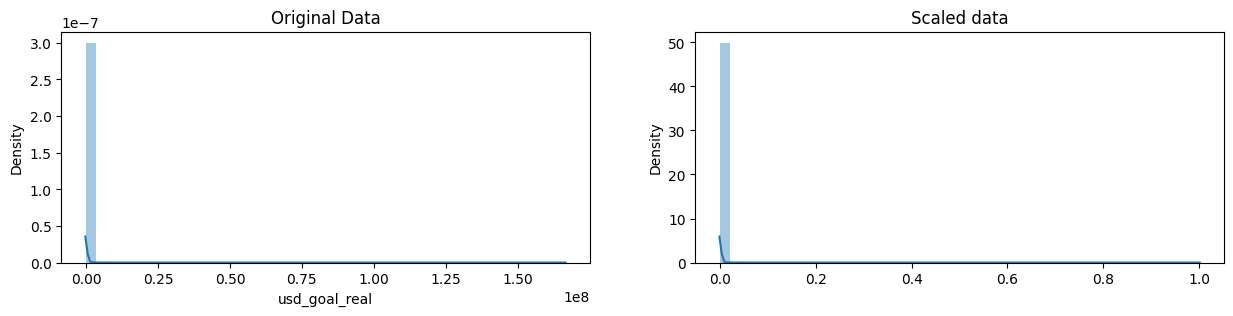

In [31]:
usd_goal = ks_17[['usd_goal_real']]
scaled_data = minmax_scaling(usd_goal, columns=['usd_goal_real'])

# plot the original & scaled data together to compare
fig, ax = plt.subplots(1, 2, figsize=(15, 3))
sns.distplot(ks_17.usd_goal_real, ax=ax[0])
ax[0].set_title("Original Data")
sns.distplot(scaled_data, ax=ax[1])
ax[1].set_title("Scaled data")

Text(0.5, 1.0, 'Scaled data')

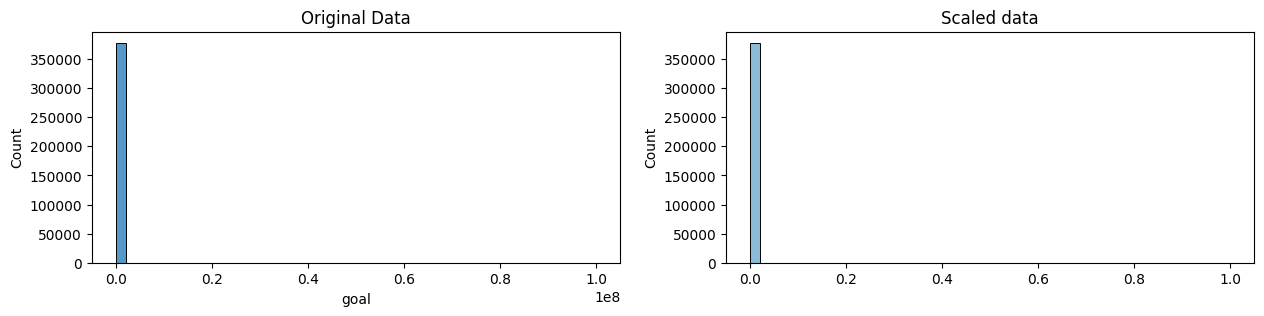

In [35]:
goal_data = ks_17[['goal']]
scaled_goal_data = minmax_scaling(goal_data, columns=['goal'])
fig, ax = plt.subplots(1, 2, figsize=(15, 3))
sns.histplot(ks_17.goal, ax=ax[0], bins=50)
ax[0].set_title("Original Data")
sns.histplot(scaled_goal_data, ax=ax[1], bins=50, legend=False)
ax[1].set_title("Scaled data")

/tmp/ipykernel_1980/3036134244.py:7: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(positive_pledges, ax=ax[0])
/tmp/ipykernel_1980/3036134244.py:9: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(normalized_pledges, ax=ax[1])


Text(0.5, 1.0, 'Normalized data')

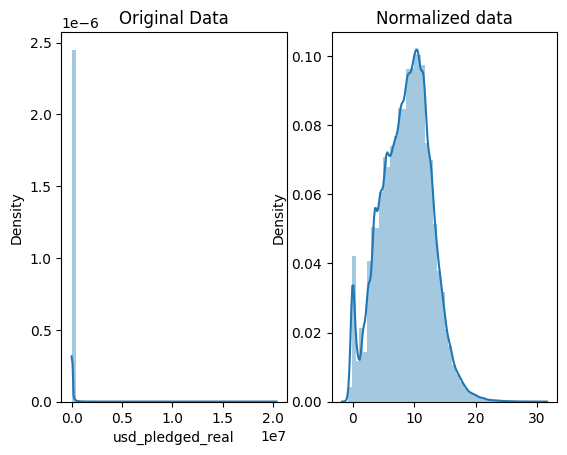

In [36]:
index_of_positive_pledges = ks_17.usd_pledged_real > 0
positive_pledges = ks_17.usd_pledged_real.loc[index_of_positive_pledges]
normalized_pledges = stats.boxcox(positive_pledges)[0]

# plot both together to compare
fig, ax=plt.subplots(1,2)
sns.distplot(positive_pledges, ax=ax[0])
ax[0].set_title("Original Data")
sns.distplot(normalized_pledges, ax=ax[1])
ax[1].set_title("Normalized data")

Text(0.5, 1.0, 'Normalized data')

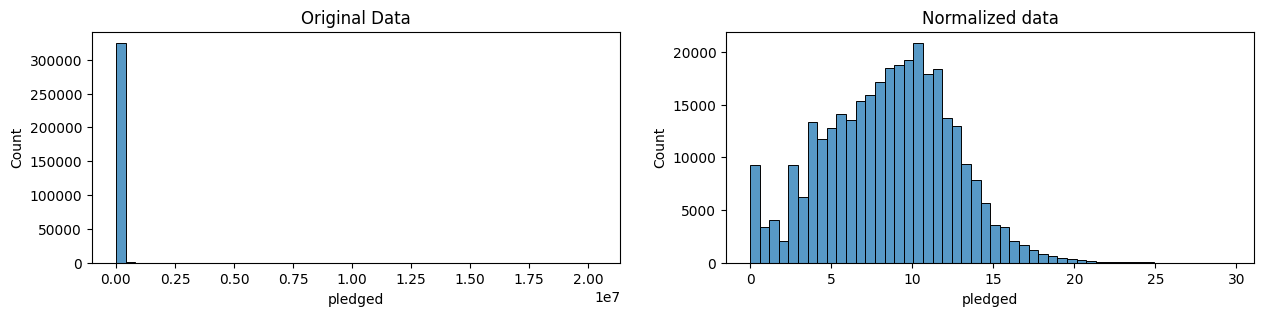

In [37]:
index_positive_pledges = ks_17.pledged > 0
positive_pledges = ks_17.pledged.loc[index_positive_pledges]

normalized_pledges = pd.Series(stats.boxcox(positive_pledges)[0],name='pledged', index=positive_pledges.index)
fig, ax = plt.subplots(1, 2, figsize=(15, 3))

#plot
sns.histplot(positive_pledges, ax=ax[0], bins=50)
ax[0].set_title("Original Data")
sns.histplot(normalized_pledges, ax=ax[1], bins=50)
ax[1].set_title("Normalized data")